---
# <font color="#CA3532">Deep Learning Fundamentals and Basic Tools (2026/2027) - Final project</font>
---


In this project you will implement and compare four deep-learning architectures for multiclass human activity recognition:

- Deep Neural Network (DNN)
- Recurrent Neural Network (RNN)
- 1D Convolutional Neural Network (CNN)
- Long Short-Term Memory Network (LSTM)

You will work with the **UCI Human Activity Recognition Using Smartphones (UCI HAR)** dataset.

You must compare predictive performance, class-level errors, convergence, model complexity, training time, inference time, and stability across repeated runs.

### <font color="#0da432">Imports</font>

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

from src.models import (
    DNNClassifier,
    RNNClassifier,
    CNNClassifier,
    LSTMClassifier,
)
from src.training import fit
from src.evaluation import (
    evaluate_model,
    count_parameters,
    measure_inference_time,
    measure_inference_stats,
    model_size_mb,
)
from src.utils import set_seed, get_device, hardware_info

PROJECT_ROOT = Path.cwd()

metrics_dir = PROJECT_ROOT / "results" / "metrics"
figures_dir = PROJECT_ROOT / "results" / "figures"
models_dir = PROJECT_ROOT / "results" / "models"
for directory in (metrics_dir, figures_dir, models_dir):
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = get_device()
pd.set_option("display.precision", 4)
print("Device:", DEVICE)

Device: cuda


### <font color="#0da432">Hardware</font>

All timings in this notebook were measured on the machine below. Training and inference run on the GPU when one is available.

In [2]:
pd.Series(hardware_info(), name="value").to_frame()

,value
Python,3.10.12
PyTorch,2.14.0+cu130
OS,Linux 6.8.0-138-generic
CPU,Intel(R) Core(TM) i7-10870H CPU @ 2.20GHz
CPU cores,16
CUDA available,True
RAM (GB),15.5
GPU,NVIDIA GeForce GTX 1650
GPU memory (GB),3.6
CUDA,13.0


### <font color="#0da432">Dataset</font>

The provided CSVs are the pre-processed version of UCI HAR: every row is a 2.56 s window (50 % overlap) summarised by **561 engineered features** (time and frequency domain statistics of the body/gravity acceleration and gyroscope signals), plus the `subject` id and the `Activity` label. The raw `(128, 9)` inertial signals are **not** included, so every architecture receives the same 561-dimensional vector:

* **DNN** – the vector as is, `(batch, 561)`.
* **CNN / RNN / LSTM** – the vector read as a sequence of 561 steps with one channel, `(batch, 561, 1)` (`src.models._as_sequence` adds the channel axis).

The "sequence" is therefore the column order of the feature table. It is not physical time, but it is not random either: related features are contiguous (e.g. `tBodyAcc-mean()-X, -Y, -Z`, then `-std()`, …; FFT band energies are ordered by frequency), so there is local structure a convolution or a recurrence can pick up.

**Validation split.** The official train/test split is by subject (21 vs 9 volunteers). The validation set is built the same way, holding out whole training subjects with `GroupShuffleSplit`. A random row split would put overlapping windows of the same person in train and validation, which inflates validation scores and makes early stopping less representative of the unseen-subject test set. The scaler is fitted on the training part only.

In [3]:
def find_data_dir():
    candidates = [
        PROJECT_ROOT / "data" / "final_project",
        PROJECT_ROOT.parent / "data" / "final_project",
        PROJECT_ROOT.parent / "repo" / "data" / "final_project",
    ]
    for candidate in candidates:
        if (candidate / "train.csv").exists():
            return candidate
    raise FileNotFoundError("train.csv not found in: " + ", ".join(map(str, candidates)))


DATA_DIR = find_data_dir()
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

TARGET = "Activity"
DROP_COLUMNS = ["subject", TARGET]
FEATURE_COLUMNS = [col for col in train_df.columns if col not in DROP_COLUMNS]

X = train_df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
X_test = test_df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(train_df[TARGET]).astype(np.int64)
y_test = label_encoder.transform(test_df[TARGET]).astype(np.int64)
class_names = list(label_encoder.classes_)

# Validation split by subject (no subject appears in both train and validation)
groups = train_df["subject"].to_numpy()
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(splitter.split(X, y, groups))

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]

# Scale using ONLY training data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

n_features = X_train.shape[1]      # 561
sequence_length = n_features       # sequence models read the vector as 561 steps ...
n_channels = 1                     # ... with one value per step
n_classes = len(class_names)

print("Train subjects:     ", sorted(set(groups[train_idx])))
print("Validation subjects:", sorted(set(groups[val_idx])))
print("Test subjects:      ", sorted(test_df["subject"].unique()))
print(f"Shapes: train {X_train.shape}, val {X_val.shape}, test {X_test.shape}")

Train subjects:      [np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(26), np.int64(28), np.int64(29), np.int64(30)]
Validation subjects: [np.int64(1), np.int64(3), np.int64(15), np.int64(25), np.int64(27)]
Test subjects:       [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]
Shapes: train (5551, 561), val (1801, 561), test (2947, 561)


#### Class distribution

The six classes are mildly imbalanced (the largest class has about 1.4× as many samples as the smallest), and the imbalance is similar in all three splits.

,train,validation,test,train %,validation %,test %
class,,,,,,
LAYING,1076,331,537,19.4,18.4,18.2
SITTING,993,293,491,17.9,16.3,16.7
STANDING,1053,321,532,19.0,17.8,18.1
WALKING,888,338,496,16.0,18.8,16.8
WALKING_DOWNSTAIRS,744,242,420,13.4,13.4,14.3
WALKING_UPSTAIRS,797,276,471,14.4,15.3,16.0


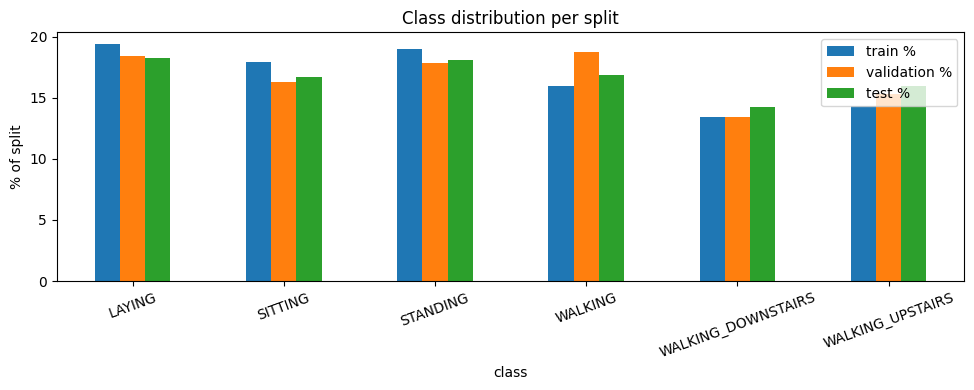

In [4]:
split_counts = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().sort_index().to_numpy(),
    "validation": pd.Series(y_val).value_counts().sort_index().to_numpy(),
    "test": pd.Series(y_test).value_counts().sort_index().to_numpy(),
}, index=pd.Index(class_names, name="class"))

split_share = (split_counts / split_counts.sum()).add_suffix(" %") * 100
display(pd.concat([split_counts, split_share.round(1)], axis=1))

ax = split_share.plot(kind="bar", figsize=(10, 4), rot=20)
ax.set_ylabel("% of split")
ax.set_title("Class distribution per split")
plt.tight_layout()
plt.savefig(figures_dir / "class_distribution.png", dpi=150)
plt.show()

### <font color="#0da432">Visualize Features</font>

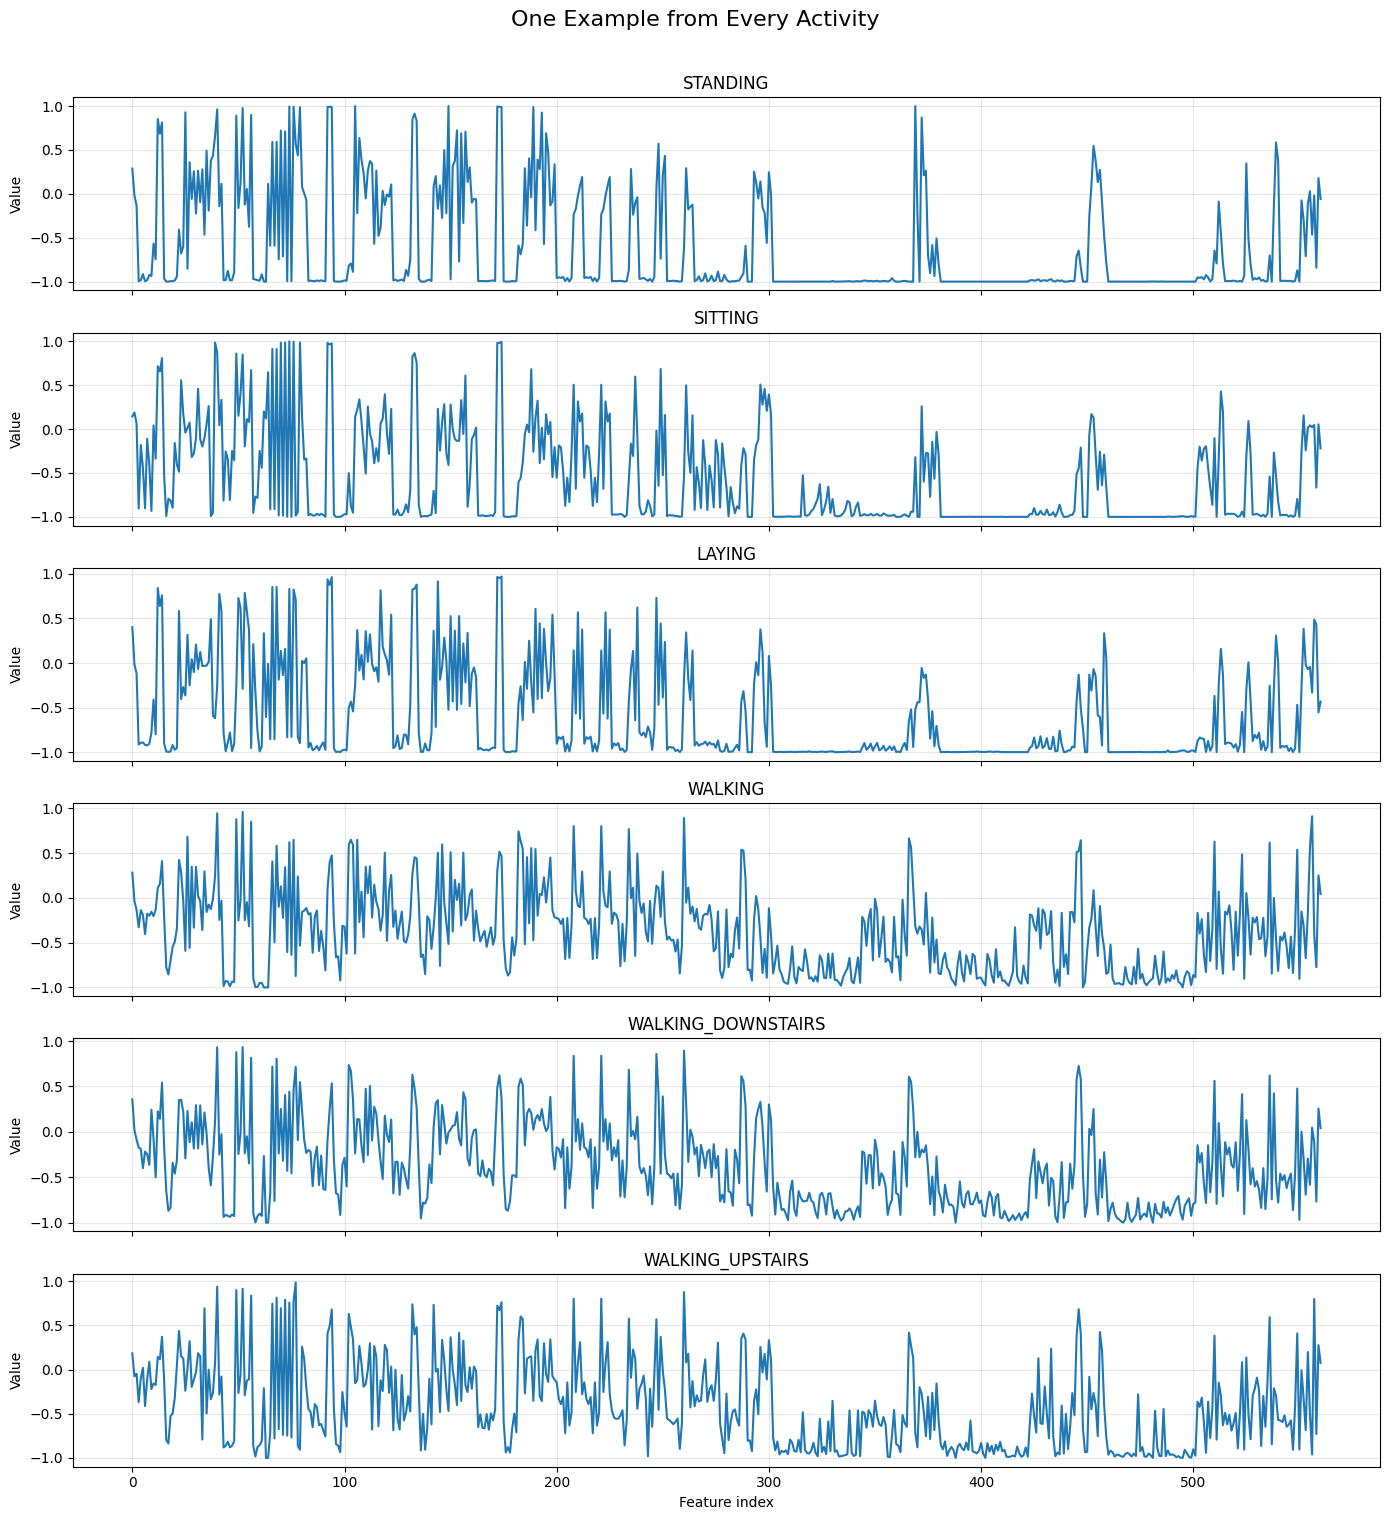

In [5]:
activities = train_df[TARGET].unique()

fig, axes = plt.subplots(
    len(activities),
    1,
    figsize=(14, 2.5 * len(activities)),
    sharex=True
)

for ax, activity in zip(axes, activities):
    sample = (
        train_df.loc[train_df[TARGET] == activity, FEATURE_COLUMNS]
        .iloc[0]
        .to_numpy(dtype=np.float32)
    )
    ax.plot(sample)
    ax.set_title(activity)
    ax.set_ylabel("Value")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Feature index")
fig.suptitle("One Example from Every Activity", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

### <font color="#0da432">Visualize the Sequences Seen by the Models</font>

The raw inertial signals are not part of the provided files, so this section shows the input the sequence models actually process: the standardised 561-step feature vector. The heatmap shows the class mean of each step and the line plot shows two static and two dynamic activities.

Two observations matter later:

* the three **dynamic** activities (walking, upstairs, downstairs) differ strongly from the three **static** ones over most of the vector;
* **SITTING** and **STANDING** have almost identical profiles, so they should be the hardest pair to separate for every model.

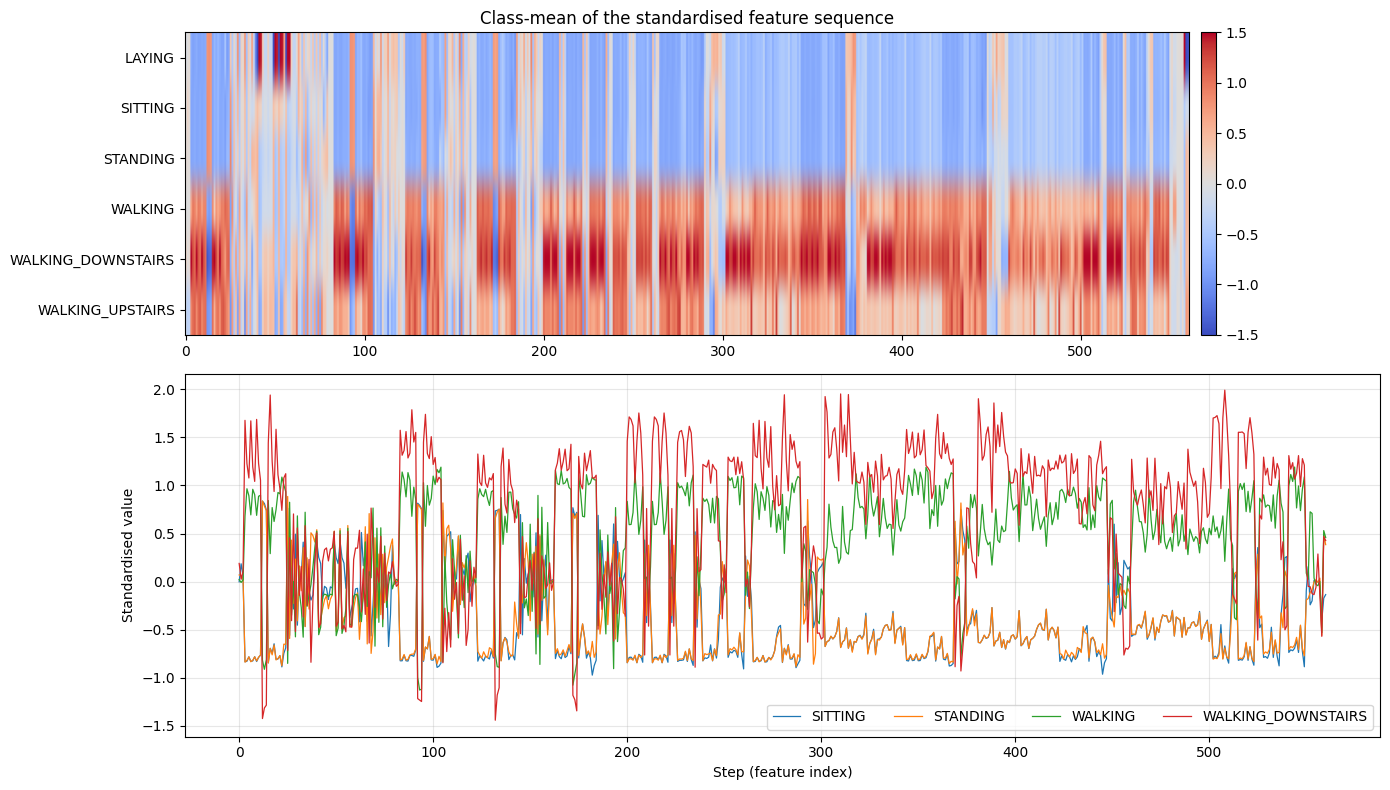

Euclidean distance between class-mean vectors:


,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
LAYING,0.0,8.4,10.4,31.5,39.3,30.2
SITTING,8.4,0.0,3.9,30.3,38.5,28.8
STANDING,10.4,3.9,0.0,30.0,38.2,28.3
WALKING,31.5,30.3,30.0,0.0,12.1,10.2
WALKING_DOWNSTAIRS,39.3,38.5,38.2,12.1,0.0,15.4
WALKING_UPSTAIRS,30.2,28.8,28.3,10.2,15.4,0.0


In [6]:
class_means = pd.DataFrame(X_train).groupby(y_train).mean()
class_means.index = class_names

fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={"height_ratios": [1, 1.2]})

im = axes[0].imshow(class_means, aspect="auto", cmap="coolwarm", vmin=-1.5, vmax=1.5)
axes[0].set_yticks(range(n_classes), class_names)
axes[0].set_title("Class-mean of the standardised feature sequence")
fig.colorbar(im, ax=axes[0], pad=0.01)

for activity in ["SITTING", "STANDING", "WALKING", "WALKING_DOWNSTAIRS"]:
    axes[1].plot(class_means.loc[activity].to_numpy(), label=activity, lw=0.9)
axes[1].set_xlabel("Step (feature index)")
axes[1].set_ylabel("Standardised value")
axes[1].legend(ncol=4)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(figures_dir / "class_mean_sequences.png", dpi=150)
plt.show()

static = ["LAYING", "SITTING", "STANDING"]
distance = pd.DataFrame(
    [[np.linalg.norm(class_means.loc[a] - class_means.loc[b]) for b in class_names] for a in class_names],
    index=class_names, columns=class_names,
)
print("Euclidean distance between class-mean vectors:")
distance.round(1)

## <font color="#0da432">Implementation Requirements</font>
You must implement the backend yourself.

Required files:

```text
src/models.py
src/training.py
src/evaluation.py
```

## `src/models.py`

Implement:

```python
DNNClassifier
RNNClassifier
CNNClassifier
LSTMClassifier
```

All models receive the same underlying information and must ultimately output:

```text
(batch_size, 6)
```

logits/scores.

### DNN

Transform:

```text
(batch, 128, 9)
```

into an appropriate vector representation.

### RNN

Process the 128 time steps sequentially with a vanilla recurrent architecture.

### CNN

Use one-dimensional convolution over the temporal dimension.

### LSTM

Use an LSTM-based sequence representation for classification.

Important architectural parameters should be configurable.

##  `src/training.py`

Implement:

```python
fit(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    **kwargs
)
```

It must return at least:

```python
{
    "model": ...,
    "history": {
        "train_loss": ...,
        "val_loss": ...,
        "train_accuracy": ...,
        "val_accuracy": ...
    },
    "training_time": ...,
    "epochs_completed": ...
}
```

Support appropriate training settings including epochs, batch size, learning rate, seed, device, and early stopping.

##  `src/evaluation.py`

Implement:

```python
evaluate_model(model, X, y, **kwargs)
count_parameters(model)
measure_inference_time(model, X, **kwargs)
```

`evaluate_model` must return at least:

```python
{
    "accuracy": ...,
    "macro_precision": ...,
    "macro_recall": ...,
    "macro_f1": ...,
    "weighted_f1": ...,
    "predictions": ...
}
```

##  `src/utils.py`

Implement:

```python
set_seed(seed)
```

The function must set the relevant random seeds for reproducibility.

# Instantiate DNN, RNN, CNN and LSTM

You may add additional keyword arguments supported by your implementation.

Document your final architecture choices.

Architectures are configured in `ARCH_CONFIG` and built through `build_model`, which seeds every RNG **before** the weights are initialised. The repeated-seed and controlled experiments reuse the same function, so every run starts from fresh weights.

The configuration was chosen on the **validation set** only. One example: summarising the recurrent outputs with the last hidden state gave much better validation accuracy than mean pooling (seed 42: RNN 0.84 vs 0.63, LSTM 0.92 vs 0.71), so `pooling="last"` is used for both recurrent models.

In [7]:
SEED = 42

ARCH_CONFIG = {
    "DNN": dict(hidden_dims=(256, 128), dropout=0.3, batch_norm=True),
    "CNN": dict(channels=(32, 64, 128), kernel_size=5, pool_size=2, dropout=0.3),
    "RNN": dict(hidden_size=64, num_layers=1, dropout=0.2, pooling="last"),
    "LSTM": dict(hidden_size=64, num_layers=1, dropout=0.2, pooling="last"),
}

MODEL_CLASSES = {
    "DNN": DNNClassifier,
    "CNN": CNNClassifier,
    "RNN": RNNClassifier,
    "LSTM": LSTMClassifier,
}


def build_model(name, seed, **overrides):
    """Fresh, seeded instance of architecture `name`."""
    set_seed(seed)
    config = {**ARCH_CONFIG[name], **overrides}
    if name == "DNN":
        return DNNClassifier(
            sequence_length=sequence_length, n_features=n_channels, n_classes=n_classes, **config
        )
    return MODEL_CLASSES[name](input_size=n_channels, n_classes=n_classes, **config)


models = {name: build_model(name, SEED) for name in ["DNN", "RNN", "CNN", "LSTM"]}
dnn_model, rnn_model, cnn_model, lstm_model = (models[k] for k in ["DNN", "RNN", "CNN", "LSTM"])

for name, model in models.items():
    print(f"{name:5s} {count_parameters(model):>8,d} parameters")

DNN    178,310 parameters
RNN      4,678 parameters
CNN     52,806 parameters
LSTM    17,542 parameters


# Forward-Pass

In [8]:
sample_batch = torch.tensor(X_train[:8], dtype=torch.float32)

for name, model in models.items():
    model.eval()
    with torch.no_grad():
        output = model(sample_batch)

    print(
        f"{name:5s} | "
        f"input={tuple(sample_batch.shape)} | "
        f"output={tuple(output.shape)}"
    )
    assert output.shape == (8, n_classes)

DNN   | input=(8, 561) | output=(8, 6)
RNN   | input=(8, 561) | output=(8, 6)
CNN   | input=(8, 561) | output=(8, 6)
LSTM  | input=(8, 561) | output=(8, 6)


### Architecture documentation

All models end in a linear layer producing 6 logits; the softmax is part of `nn.CrossEntropyLoss`. Parameter counts are for the configuration above.

| | **DNN** | **CNN** | **RNN** | **LSTM** |
|---|---|---|---|---|
| Input | `(B, 561)` flat vector | `(B, 561, 1)` → transposed to `(B, 1, 561)` | `(B, 561, 1)`, one step per feature | `(B, 561, 1)`, one step per feature |
| Layers | `Linear(561→256)` → BN → ReLU → Dropout, `Linear(256→128)` → BN → ReLU → Dropout, `Linear(128→6)` | 3 × [`Conv1d` (k=5, same padding) → BN → ReLU → `MaxPool1d(2)`] with 32/64/128 filters, global average pooling, Dropout, `Linear(128→6)` | 1-layer Elman RNN, 64 hidden units, `tanh`; last hidden state → Dropout → `Linear(64→6)` | 1-layer LSTM, 64 hidden units (sigmoid gates, `tanh` cell); last hidden state → Dropout → `Linear(64→6)` |
| Activations | ReLU | ReLU | tanh | sigmoid / tanh |
| Dropout | 0.3 after each hidden layer | 0.3 before the classifier | 0.2 before the classifier | 0.2 before the classifier |
| Parameters | ≈178 k | ≈53 k | ≈4.7 k | ≈17.5 k |
| What "temporal" information it can use | None as such: each position has its own weight, so it sees the whole vector at once with no notion of order or locality | Local patterns of ≤ 5 neighbouring steps, combined hierarchically; receptive field ≈ 29 steps after three blocks; weights are shared along the axis and the global pooling makes it position-invariant | Full order, one step at a time, through a single hidden state; gradients have to cross up to 561 multiplications by `W_hh`, so early steps are hard to remember | Full order with gated memory; the additive cell-state path lets information from early steps survive the 561-step recursion |

Shared choices: Adam, cross-entropy, batch size 64, learning rate 1e-3, gradient clipping at norm 1.0 (needed by the recurrent models, harmless for the others), and early stopping on validation loss. Sizes were kept moderate so the models are comparable in capacity rather than tuned to the limit.

# Training

Use comparable conditions.

Do not use the test set for model selection or hyperparameter tuning.

All four models use the same optimiser, loss, batch size, learning rate, maximum number of epochs, gradient clipping and early-stopping rule. Early stopping monitors the validation loss with patience 10, and the weights of the best epoch are restored. The cap of 100 epochs is high enough that it does not bind for any model; in a preliminary run with a cap of 50, the LSTM was still improving when it stopped.

In [9]:
TRAINING_CONFIG = {
    "epochs": 100,
    "batch_size": 64,
    "learning_rate": 1e-3,
    "patience": 10,
    "grad_clip": 1.0,
    "seed": SEED,
    "device": DEVICE,
    "verbose": False,
}

TRAINING_CONFIG

{'epochs': 100,
 'batch_size': 64,
 'learning_rate': 0.001,
 'patience': 10,
 'grad_clip': 1.0,
 'seed': 42,
 'device': device(type='cuda'),
 'verbose': False}

# Train DNN

In [10]:
dnn_result = fit(
    dnn_model,
    X_train, y_train,
    X_val, y_val,
    checkpoint_path=models_dir / "dnn_seed{}.pt".format(SEED),
    **TRAINING_CONFIG,
)

dnn_model = dnn_result["model"]

print("Training time: {:.1f} s".format(dnn_result["training_time"]))
print("Epochs:", dnn_result["epochs_completed"], "| best epoch:", dnn_result["best_epoch"])

Training time: 3.8 s
Epochs: 18 | best epoch: 8


# Train RNN

In [11]:
rnn_result = fit(
    rnn_model,
    X_train, y_train,
    X_val, y_val,
    checkpoint_path=models_dir / "rnn_seed{}.pt".format(SEED),
    **TRAINING_CONFIG,
)

rnn_model = rnn_result["model"]

print("Training time: {:.1f} s".format(rnn_result["training_time"]))
print("Epochs:", rnn_result["epochs_completed"], "| best epoch:", rnn_result["best_epoch"])

Training time: 13.3 s
Epochs: 55 | best epoch: 45


# Train CNN

In [12]:
cnn_result = fit(
    cnn_model,
    X_train, y_train,
    X_val, y_val,
    checkpoint_path=models_dir / "cnn_seed{}.pt".format(SEED),
    **TRAINING_CONFIG,
)

cnn_model = cnn_result["model"]

print("Training time: {:.1f} s".format(cnn_result["training_time"]))
print("Epochs:", cnn_result["epochs_completed"], "| best epoch:", cnn_result["best_epoch"])

Training time: 14.4 s
Epochs: 23 | best epoch: 13


# Train LSTM

In [13]:
lstm_result = fit(
    lstm_model,
    X_train, y_train,
    X_val, y_val,
    checkpoint_path=models_dir / "lstm_seed{}.pt".format(SEED),
    **TRAINING_CONFIG,
)

lstm_model = lstm_result["model"]

print("Training time: {:.1f} s".format(lstm_result["training_time"]))
print("Epochs:", lstm_result["epochs_completed"], "| best epoch:", lstm_result["best_epoch"])

Training time: 19.0 s
Epochs: 35 | best epoch: 25


# Collect Training Results

In [14]:
training_results = {
    "DNN": dnn_result,
    "RNN": rnn_result,
    "CNN": cnn_result,
    "LSTM": lstm_result,
}

trained_models = {
    name: result["model"]
    for name, result in training_results.items()
}

# Loss Curves

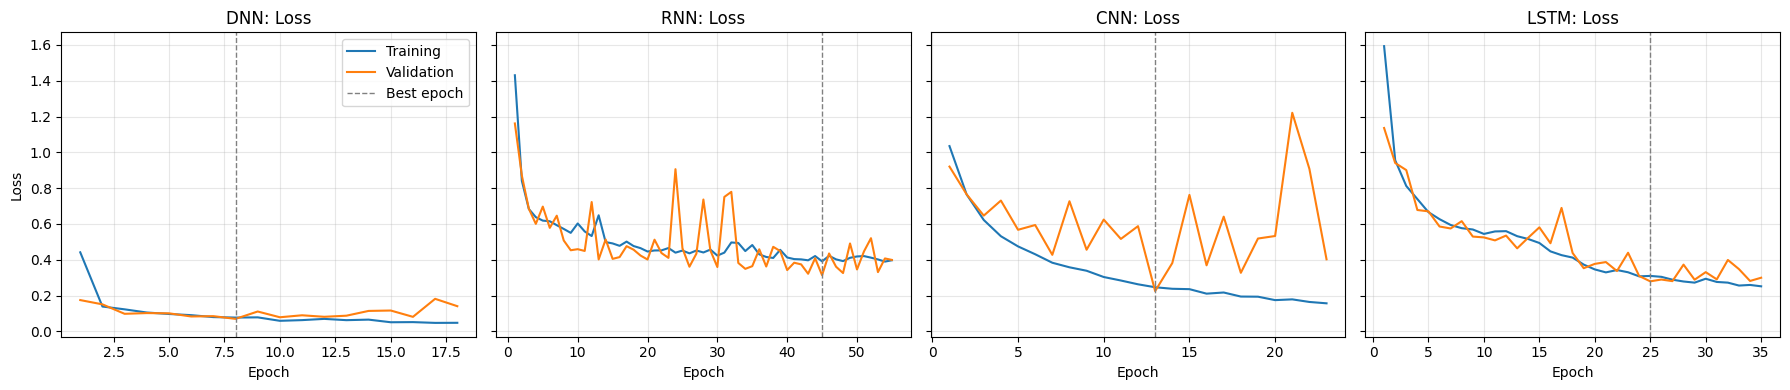

In [15]:
def plot_curves(key, ylabel, filename):
    fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
    for ax, (name, result) in zip(axes, training_results.items()):
        history = result["history"]
        epochs = np.arange(1, len(history[f"train_{key}"]) + 1)
        ax.plot(epochs, history[f"train_{key}"], label="Training")
        ax.plot(epochs, history[f"val_{key}"], label="Validation")
        ax.axvline(result["best_epoch"], color="grey", ls="--", lw=1, label="Best epoch")
        ax.set_title(f"{name}: {ylabel}")
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel(ylabel)
    axes[0].legend()
    plt.tight_layout()
    plt.savefig(figures_dir / filename, dpi=150)
    plt.show()


plot_curves("loss", "Loss", "loss_curves.png")

#  Accuracy Curves

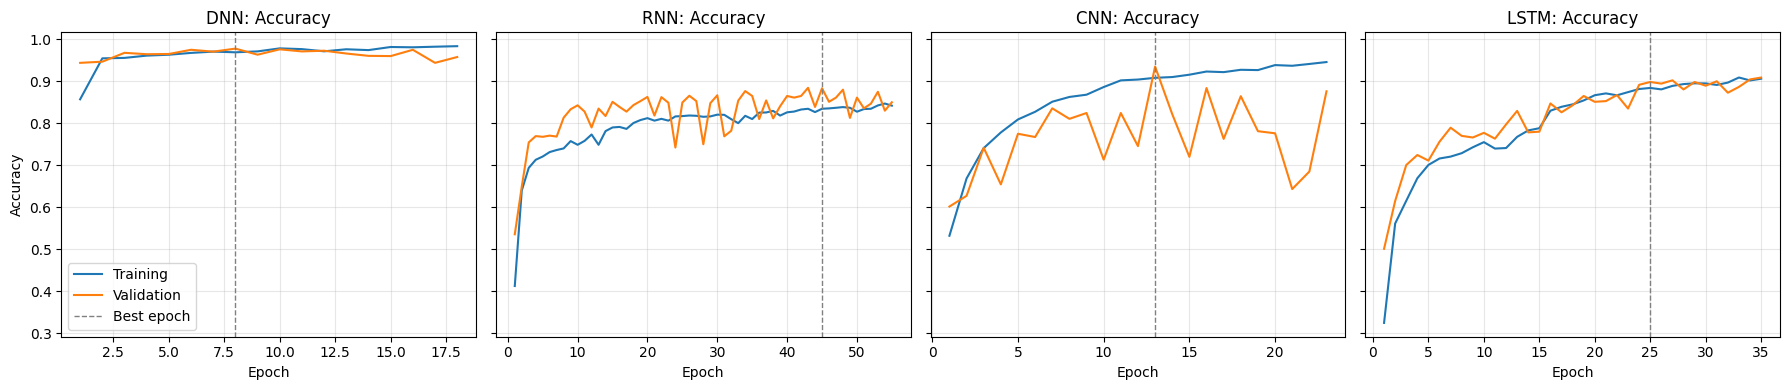

In [16]:
plot_curves("accuracy", "Accuracy", "accuracy_curves.png")

In [17]:
training_summary = pd.DataFrame([
    {
        "Model": name,
        "Epochs": result["epochs_completed"],
        "Best epoch": result["best_epoch"],
        "Train loss @best": result["history"]["train_loss"][result["best_epoch"] - 1],
        "Val loss @best": result["history"]["val_loss"][result["best_epoch"] - 1],
        "Train acc @best": result["history"]["train_accuracy"][result["best_epoch"] - 1],
        "Val acc @best": result["history"]["val_accuracy"][result["best_epoch"] - 1],
        "Gap (train-val acc)": (
            result["history"]["train_accuracy"][result["best_epoch"] - 1]
            - result["history"]["val_accuracy"][result["best_epoch"] - 1]
        ),
        # mean absolute epoch-to-epoch change of the validation loss: a simple stability measure
        "Val-loss jitter": np.mean(np.abs(np.diff(result["history"]["val_loss"]))),
    }
    for name, result in training_results.items()
]).set_index("Model")

training_summary

,Epochs,Best epoch,Train loss @best,Val loss @best,Train acc @best,Val acc @best,Gap (train-val acc),Val-loss jitter
Model,,,,,,,,
DNN,18,8,0.0773,0.0700,0.9685,0.9772,-0.0088,0.0248
RNN,55,45,0.3912,0.3138,0.8341,0.8828,-0.0488,0.1219
CNN,23,13,0.2466,0.2251,0.9078,0.9345,-0.0267,0.2374
LSTM,35,25,0.3099,0.2796,0.8836,0.8978,-0.0142,0.0710


### Training behavior analysis

For each architecture explain:

- convergence speed;
- overfitting;
- underfitting;
- stability;
- early stopping;
- train/validation gap.


#### Training behaviour – observations (seed 42, curves and table above)

* **DNN.** Converges almost immediately: validation accuracy is already 0.94 after one epoch and peaks at 0.977 in epoch 8. After that the training loss keeps falling (0.077 → 0.048) while the validation loss rises (0.070 → 0.14). This is the start of **overfitting**, and early stopping catches it, restoring epoch 8 and stopping at 18. The curves are smooth (lowest val-loss jitter, 0.025).
* **CNN.** The training loss falls steadily, but the validation loss is **very unstable**. It jumps between 0.23 and 1.2 from one epoch to the next, and validation accuracy ranges from 0.60 to 0.93 (jitter 0.24, ten times the DNN's). Training accuracy keeps rising to 0.95 while validation does not follow, so the network partly fits subject-specific patterns. The restored epoch 13 is a favourable spike in a noisy curve, which explains the large seed-to-seed spread seen later.
* **RNN.** Fast start (0.75 val acc after 3 epochs), then a plateau around 0.82–0.88 with large spikes in the validation loss. It ran 55 epochs and its train and validation losses at the end are equal (0.40 vs 0.40), so it is **underfitting** rather than overfitting. One 64-unit `tanh` state cannot carry what it needs across 561 steps.
* **LSTM.** The slowest to converge (it starts lowest, at 0.50 val acc, and needs 25 epochs to reach its best), but the climb is smooth and train and validation curves stay together. At the best epoch, train and validation accuracy are 0.884 and 0.898 and still rising slowly. It is mildly **underfitting**, which motivated the hidden-size experiment below.
* **Negative train–val gap.** For every model the training accuracy at the best epoch is slightly *below* the validation accuracy. Two effects cause this: training metrics are averaged over the epoch with dropout active, and the five validation subjects turn out to be easier than average (all models score higher on validation than on the test subjects). So no model was overfitting at the epoch that early stopping restored.
* **Early stopping** decided the length of every run. No run reached the 100-epoch cap (17–55 epochs), so every model was compared at its own best validation epoch.

# Final Test Evaluation



Report:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1
- Weighted F1
- Per-class metrics

The test set is used **once**, here, with the weights restored from the best validation epoch. It played no part in choosing architectures, hyper-parameters or the stopping epoch.

In [18]:
test_results = {}

for name, model in trained_models.items():
    test_results[name] = evaluate_model(model, X_test, y_test, class_names=class_names)

comparison_df = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": result["accuracy"],
        "Macro Precision": result["macro_precision"],
        "Macro Recall": result["macro_recall"],
        "Macro F1": result["macro_f1"],
        "Weighted F1": result["weighted_f1"],
    }
    for name, result in test_results.items()
])

comparison_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,DNN,0.9416,0.9465,0.9404,0.9419,0.9417
1,RNN,0.7564,0.7571,0.7476,0.7493,0.7573
2,CNN,0.8633,0.8737,0.8605,0.8598,0.8621
3,LSTM,0.8398,0.8400,0.8348,0.8347,0.8388


### Macro vs. weighted metrics

* **Macro** averages compute the metric separately for each class and then take the plain mean, so every activity counts the same no matter how many samples it has.
* **Weighted** averages weight each class's score by its support (number of true samples), so frequent classes count more. Weighted recall equals accuracy.

The difference matters when classes are imbalanced or when the model does very differently on small and large classes. A model that fails on a rare class can still get a high weighted F1, while its macro F1 drops. In UCI HAR the imbalance is mild (420–537 test samples per class), so the two averages are expected to be close, and they are (table above). They are not interchangeable, though. The hardest classes, SITTING and STANDING, are among the larger ones, so their errors count a little *more* in the weighted average. Because every activity matters equally in an activity-recognition application, **macro F1 is the main metric** in the rest of the notebook.

# Per-Class Classification Reports

In [19]:
for name, result in test_results.items():
    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)
    print(
        classification_report(
            y_test,
            result["predictions"],
            target_names=class_names,
            digits=4,
        )
    )


DNN
                    precision    recall  f1-score   support

            LAYING     1.0000    0.9777    0.9887       537
           SITTING     0.9592    0.8615    0.9077       491
          STANDING     0.8624    0.9662    0.9113       532
           WALKING     0.9046    0.9940    0.9472       496
WALKING_DOWNSTAIRS     0.9826    0.9429    0.9623       420
  WALKING_UPSTAIRS     0.9703    0.9002    0.9339       471

          accuracy                         0.9416      2947
         macro avg     0.9465    0.9404    0.9419      2947
      weighted avg     0.9451    0.9416    0.9417      2947


RNN
                    precision    recall  f1-score   support

            LAYING     1.0000    0.9497    0.9742       537
           SITTING     0.8821    0.7006    0.7809       491
          STANDING     0.7619    0.9023    0.8262       532
           WALKING     0.6081    0.6633    0.6345       496
WALKING_DOWNSTAIRS     0.6203    0.6262    0.6232       420
  WALKING_UPSTAIRS     0.6

In [20]:
per_class_f1 = pd.DataFrame(
    {name: result["per_class"]["f1"] for name, result in test_results.items()}
)
per_class_f1["Support"] = test_results["DNN"]["per_class"]["support"]
per_class_f1.style.format("{:.4f}", subset=list(test_results)).background_gradient(
    cmap="RdYlGn", subset=list(test_results), vmin=0.5, vmax=1.0
)

,DNN,RNN,CNN,LSTM,Support
class,,,,,
LAYING,0.9887,0.9742,0.9897,0.9963,537
SITTING,0.9077,0.7809,0.7500,0.7825,491
STANDING,0.9113,0.8262,0.8346,0.8306,532
WALKING,0.9472,0.6345,0.8727,0.8050,496
WALKING_DOWNSTAIRS,0.9623,0.6232,0.8265,0.7666,420
WALKING_UPSTAIRS,0.9339,0.6566,0.8851,0.8270,471


# Confusion Matrices

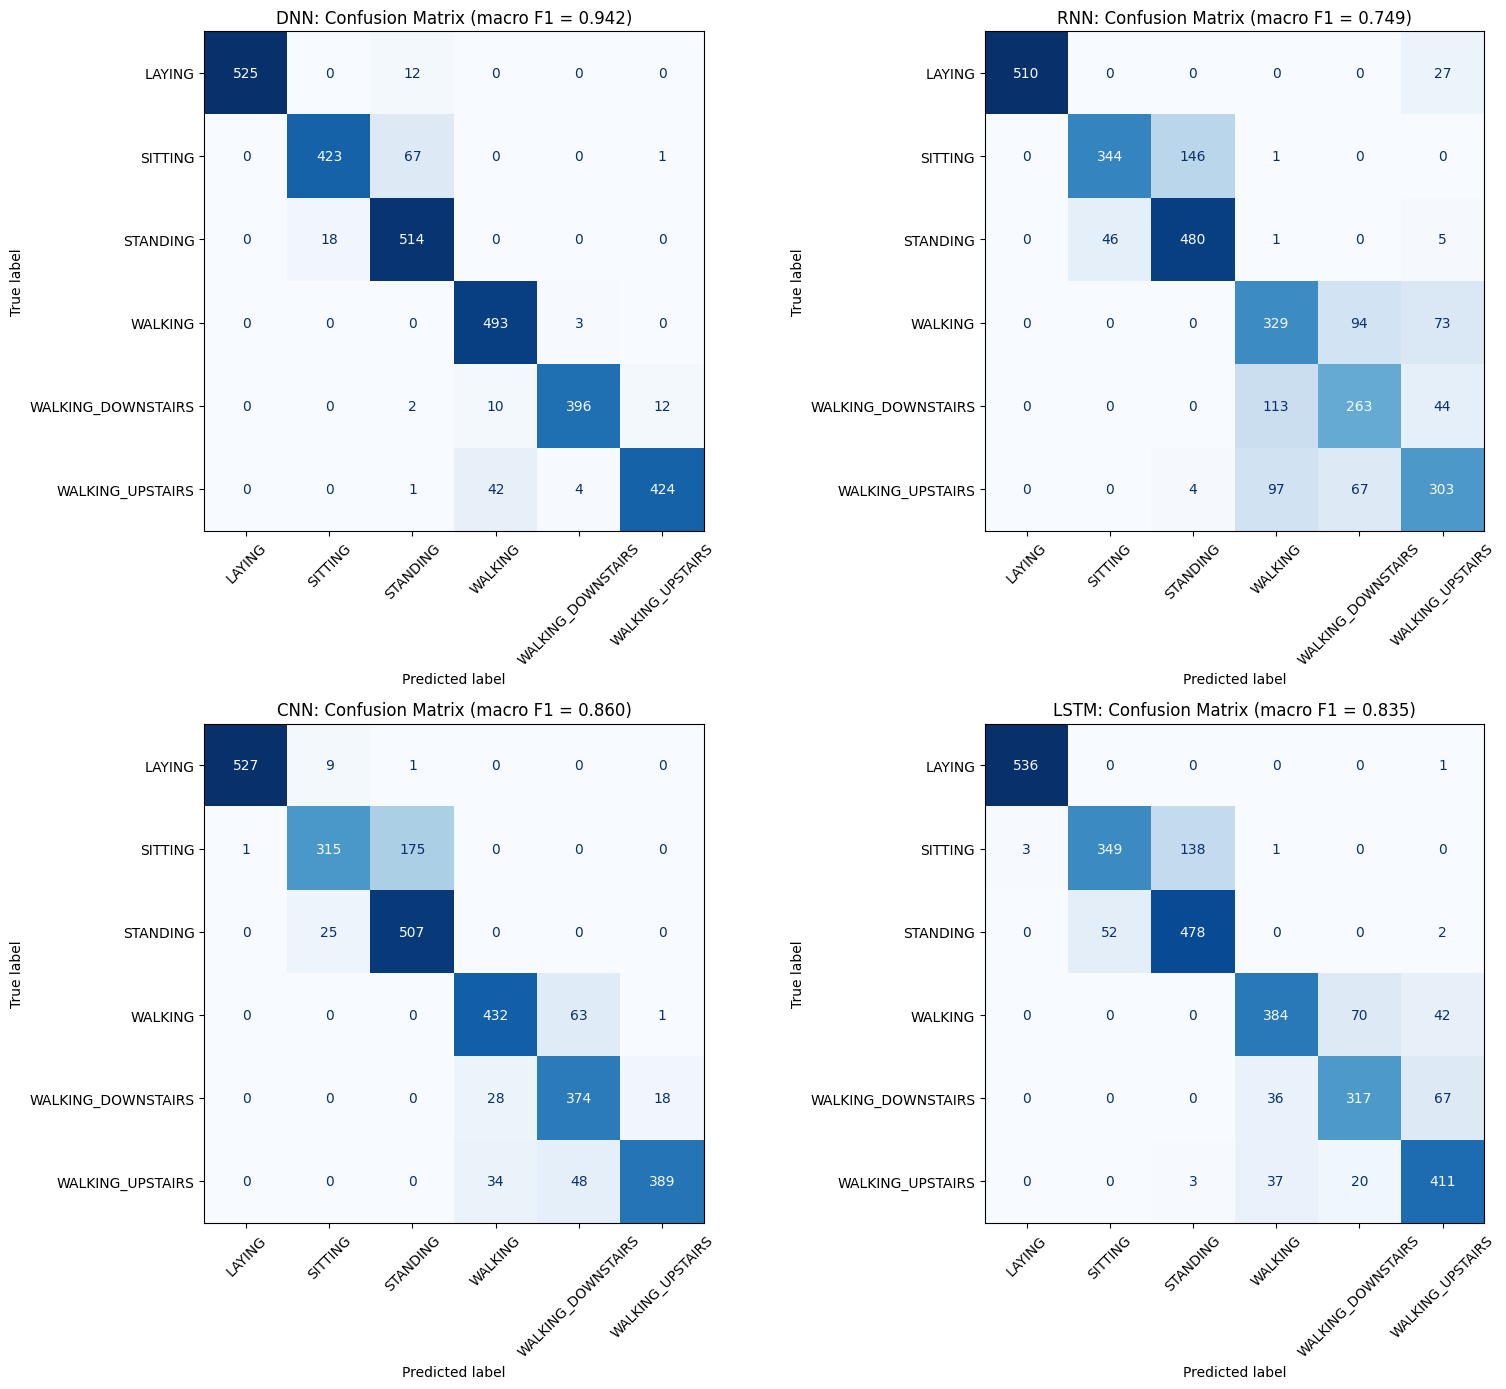

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

for ax, (name, result) in zip(axes.ravel(), test_results.items()):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=result["confusion_matrix"],
        display_labels=class_names,
    )
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}: Confusion Matrix (macro F1 = {result['macro_f1']:.3f})")

plt.tight_layout()
plt.savefig(figures_dir / "confusion_matrices.png", dpi=150)
plt.show()

#### Most frequent confusions

For each model, the off-diagonal cells as a percentage of the true class (row-normalised confusion matrix), largest first.

In [22]:
def top_confusions(cm, k=4):
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    pairs = [
        (class_names[i], class_names[j], cm[i, j], 100 * cm_norm[i, j])
        for i in range(n_classes) for j in range(n_classes) if i != j and cm[i, j] > 0
    ]
    pairs.sort(key=lambda p: -p[2])
    return pairs[:k]


confusions_df = pd.DataFrame([
    {"Model": name, "True": t, "Predicted": p, "Count": c, "% of true class": pct}
    for name, result in test_results.items()
    for t, p, c, pct in top_confusions(result["confusion_matrix"])
])
confusions_df

,Model,True,Predicted,Count,% of true class
0,DNN,SITTING,STANDING,67,13.6456
1,DNN,WALKING_UPSTAIRS,WALKING,42,8.9172
2,DNN,STANDING,SITTING,18,3.3835
3,DNN,LAYING,STANDING,12,2.2346
4,RNN,SITTING,STANDING,146,29.7352
5,RNN,WALKING_DOWNSTAIRS,WALKING,113,26.9048
6,RNN,WALKING_UPSTAIRS,WALKING,97,20.5945
7,RNN,WALKING,WALKING_DOWNSTAIRS,94,18.9516
8,CNN,SITTING,STANDING,175,35.6415
9,CNN,WALKING,WALKING_DOWNSTAIRS,63,12.7016


In [23]:
# Errors between the static (LAYING/SITTING/STANDING) and dynamic (WALKING*) groups
static_idx = [class_names.index(c) for c in ["LAYING", "SITTING", "STANDING"]]
dynamic_idx = [i for i in range(n_classes) if i not in static_idx]

group_errors = []
for name, result in test_results.items():
    cm = result["confusion_matrix"]
    within_static = cm[np.ix_(static_idx, static_idx)].sum() - np.trace(cm[np.ix_(static_idx, static_idx)])
    within_dynamic = cm[np.ix_(dynamic_idx, dynamic_idx)].sum() - np.trace(cm[np.ix_(dynamic_idx, dynamic_idx)])
    across = cm[np.ix_(static_idx, dynamic_idx)].sum() + cm[np.ix_(dynamic_idx, static_idx)].sum()
    group_errors.append({
        "Model": name,
        "Errors within static": within_static,
        "Errors within dynamic": within_dynamic,
        "Errors static<->dynamic": across,
        "Total errors": cm.sum() - np.trace(cm),
    })

pd.DataFrame(group_errors).set_index("Model")

,Errors within static,Errors within dynamic,Errors static<->dynamic,Total errors
Model,,,,
DNN,97,71,4,172
RNN,192,488,38,718
CNN,211,192,0,403
LSTM,193,272,7,472


### Activity-specific error analysis

Explain in ypur report:

- whether recurrent models make similar errors.
- whether CNN differs from RNN/LSTM.
- whether flattening disadvantages the DNN.


#### Confusion-matrix analysis (seed 42, plus per-class F1 over three seeds)

**Easiest class – LAYING.** Its F1 is 0.97–1.00 for every model and every seed. Lying down changes the orientation of the gravity vector, which shifts many features at once (the darkest band at steps ≈ 40–60 in the class-mean heatmap). LAYING is also the static class farthest from the other two (distance 8.4 to SITTING and 10.4 to STANDING, versus 3.9 between SITTING and STANDING).

**Most confused pair – SITTING → STANDING.** This is the largest error of *every* architecture: DNN 13.6 % of true SITTING samples, LSTM 28 %, RNN 30 %, CNN 36 %. The reverse error (STANDING → SITTING) is much smaller (3–10 %). The models default to STANDING when unsure. Both postures are static with the phone on the waist, so the signals differ only in small changes of sensor orientation. Their class-mean vectors are the closest pair in the dataset, and the line plot above shows them nearly on top of each other.

**Second error family – the three walking classes.** Confusions among WALKING, UPSTAIRS and DOWNSTAIRS are small for the DNN (71 errors) but large for the sequence models (CNN 192, LSTM 272, RNN 488). In the RNN they are the dominant failure, with F1 of 0.55–0.66 for the three dynamic classes.

**Static vs. dynamic is almost never confused.** Across the four models only 0–38 of the 172–718 errors cross the static/dynamic boundary. Every architecture learns the coarse split easily, and the differences between them lie inside the two groups.

**Are the same classes hard for all architectures?** Yes for the static group: SITTING/STANDING is the hardest pair for everybody. The models differ in how they fail:

* **DNN** – smallest errors in both groups. Flattening does **not** hurt here: the input is a set of independent summary statistics, not a time series. A position-specific weight per feature is exactly what is needed, and the DNN can combine distant features freely (e.g. a gravity-angle feature at step 558 with an energy feature at step 16).
* **CNN** – handles the dynamic classes second best (mean F1 0.80–0.87) but is the **least reliable on SITTING**. Its mean F1 is only 0.50, and in two of the three seeds it collapses to 0.37, labelling most SITTING windows as STANDING. The convolution + global average pooling only "sees" local patterns of neighbouring features and averages them over the whole vector. The few position-specific features that separate sitting from standing get diluted, and whether a given run happens to pick them up depends on the seed.
* **LSTM** – the most balanced of the sequence models (mean F1 0.77–0.83 on all five non-LAYING classes, low seed variance). It does better than the CNN on SITTING (0.77 vs 0.50) but worse on the walking classes (0.78–0.81 vs 0.80–0.87).
* **RNN** – shares the LSTM's SITTING/STANDING behaviour (similar F1 of 0.79 / 0.83), so on the static classes **the two recurrent models make similar errors**. It is much worse on the walking classes. The features that separate walking from stairs are spread along the whole vector, and many lie far from the last step. The gated cell state of the LSTM can carry them to the end; the vanilla RNN's `tanh` state forgets them (vanishing gradients over 561 steps).

**Explanation from the data.** The 561-step "sequence" is a concatenation of feature blocks: time-domain stats, then FFT bands, then angles. Order only matters *within* a block, so inductive biases built for real time series (locality and translation invariance in the CNN, sequential memory in the RNN/LSTM) do not match the structure of this input. Adjacent features are related, which is why CNN and LSTM still reach 0.79–0.84 macro F1. However, the most discriminative information is *which* feature has *which* value, and that is what a fully connected layer models directly.

# Trainable Parameter Counts

In [24]:
parameter_counts = {
    name: count_parameters(model)
    for name, model in trained_models.items()
}

parameter_df = pd.DataFrame({
    "Model": list(parameter_counts.keys()),
    "Parameters": list(parameter_counts.values()),
    "Model size (MB)": [model_size_mb(m) for m in trained_models.values()],
})

parameter_df

,Model,Parameters,Model size (MB)
0,DNN,178310,0.6884
1,RNN,4678,0.0201
2,CNN,52806,0.2104
3,LSTM,17542,0.0692


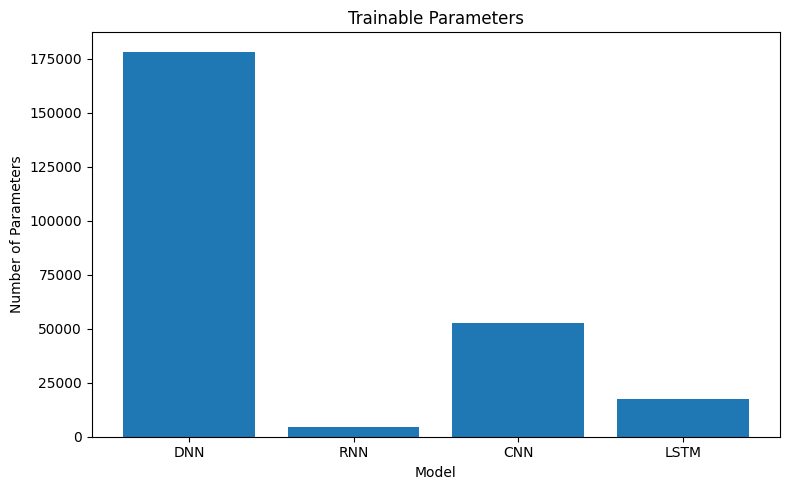

In [25]:
plt.figure(figsize=(8, 5))
plt.bar(parameter_df["Model"], parameter_df["Parameters"])
plt.title("Trainable Parameters")
plt.xlabel("Model")
plt.ylabel("Number of Parameters")
plt.tight_layout()
plt.savefig(figures_dir / "parameters.png", dpi=150)
plt.show()

# Training-Time Comparison

In [26]:
training_time_df = pd.DataFrame([
    {
        "Model": name,
        "Training Time (s)": result["training_time"],
        "Epochs": result["epochs_completed"],
        "Average Time / Epoch (s)": np.mean(result["history"]["epoch_time"]),
        "Train samples / s": len(X_train) / np.mean(result["history"]["epoch_time"]),
        "Peak GPU memory (MB)": result["peak_gpu_memory_mb"],
    }
    for name, result in training_results.items()
])

training_time_df

,Model,Training Time (s),Epochs,Average Time / Epoch (s),Train samples / s,Peak GPU memory (MB)
0,DNN,3.8019,18,0.2103,26394.1717,20.4814
1,RNN,13.2781,55,0.2411,23021.4236,175.5542
2,CNN,14.4434,23,0.6270,8852.8071,69.2490
3,LSTM,19.0382,35,0.5434,10214.9181,281.3745


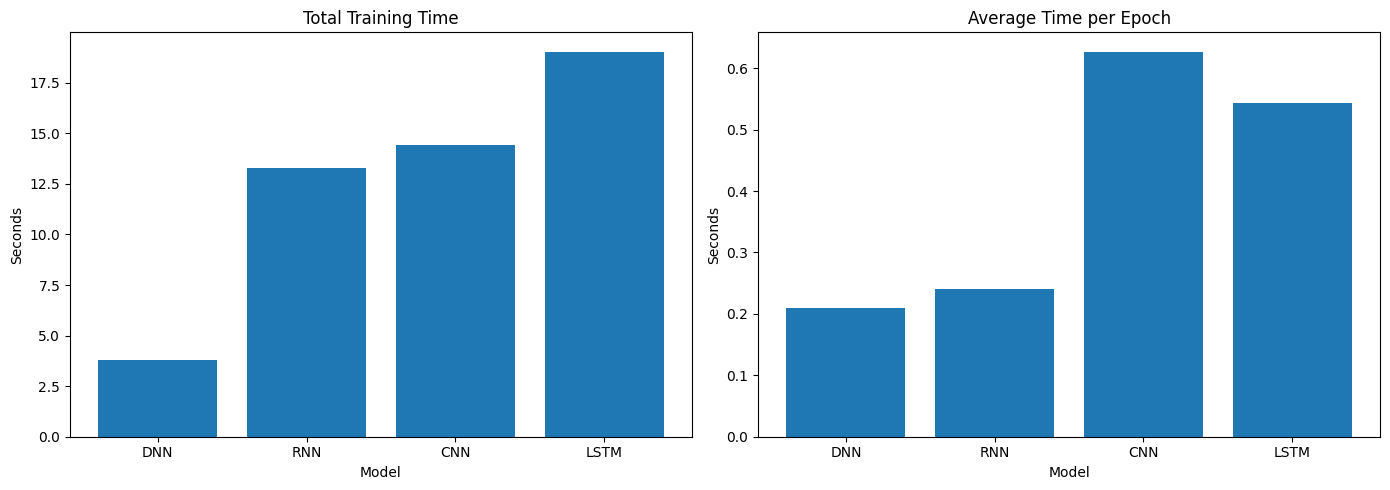

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(training_time_df["Model"], training_time_df["Training Time (s)"])
axes[0].set_title("Total Training Time")
axes[0].set_ylabel("Seconds")
axes[1].bar(training_time_df["Model"], training_time_df["Average Time / Epoch (s)"])
axes[1].set_title("Average Time per Epoch")
axes[1].set_ylabel("Seconds")
for ax in axes:
    ax.set_xlabel("Model")
plt.tight_layout()
plt.savefig(figures_dir / "training_time.png", dpi=150)
plt.show()

# Inference-Time Comparison

Inference is timed over the whole test set (2,947 samples, batch size 512) on the same device. There are 2 warm-up passes and then 10 timed passes. Data is moved to the device beforehand, so only computation is measured.

In [28]:
inference_stats = {
    name: measure_inference_stats(model, X_test, device=DEVICE)
    for name, model in trained_models.items()
}
inference_times = {name: stats["total_time_s"] for name, stats in inference_stats.items()}

inference_df = pd.DataFrame([
    {
        "Model": name,
        "Inference Time (s)": stats["total_time_s"],
        "Std (s)": stats["total_time_std_s"],
        "ms / sample": stats["time_per_sample_ms"],
        "Samples / s": stats["samples_per_second"],
    }
    for name, stats in inference_stats.items()
])

inference_df

,Model,Inference Time (s),Std (s),ms / sample,Samples / s
0,DNN,0.0015,2.6627e-05,0.0005,1.9800e+06
1,RNN,0.0179,7.1796e-04,0.0061,1.6420e+05
2,CNN,0.0644,1.8528e-04,0.0219,4.5739e+04
3,LSTM,0.0625,1.7918e-04,0.0212,4.7149e+04


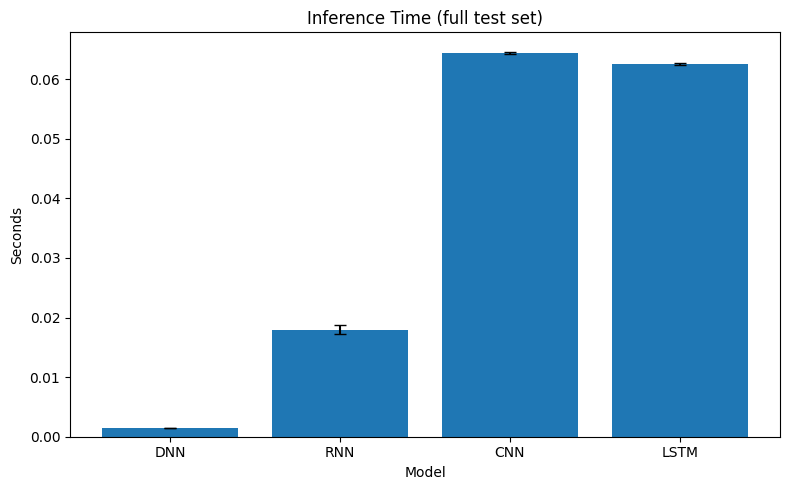

In [29]:
plt.figure(figsize=(8, 5))
plt.bar(
    inference_df["Model"],
    inference_df["Inference Time (s)"],
    yerr=inference_df["Std (s)"],
    capsize=4,
)
plt.title("Inference Time (full test set)")
plt.xlabel("Model")
plt.ylabel("Seconds")
plt.tight_layout()
plt.savefig(figures_dir / "inference_time.png", dpi=150)
plt.show()

# Complete Model Comparison

In [30]:
final_comparison = comparison_df.copy()

final_comparison["Parameters"] = final_comparison["Model"].map(parameter_counts)
final_comparison["Training Time"] = final_comparison["Model"].map({
    name: result["training_time"] for name, result in training_results.items()
})
final_comparison["Epochs"] = final_comparison["Model"].map({
    name: result["epochs_completed"] for name, result in training_results.items()
})
final_comparison["Inference Time"] = final_comparison["Model"].map(inference_times)

final_comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Parameters,Training Time,Epochs,Inference Time
0,DNN,0.9416,0.9465,0.9404,0.9419,0.9417,178310,3.8019,18,0.0015
1,RNN,0.7564,0.7571,0.7476,0.7493,0.7573,4678,13.2781,55,0.0179
2,CNN,0.8633,0.8737,0.8605,0.8598,0.8621,52806,14.4434,23,0.0644
3,LSTM,0.8398,0.8400,0.8348,0.8347,0.8388,17542,19.0382,35,0.0625


# Predictive-Metric Comparison

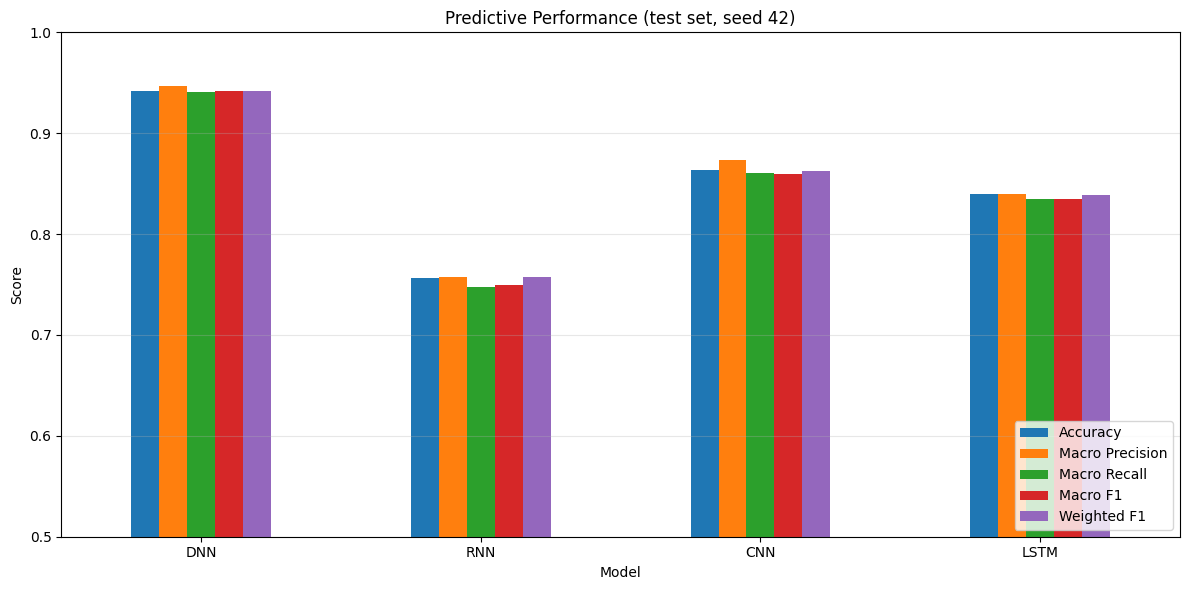

In [31]:
metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
]

final_comparison.set_index("Model")[metric_columns].plot(kind="bar", figsize=(12, 6))

plt.title("Predictive Performance (test set, seed 42)")
plt.ylabel("Score")
plt.ylim(0.5, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(figures_dir / "predictive_performance.png", dpi=150)
plt.show()

# Performance vs Computational Cost

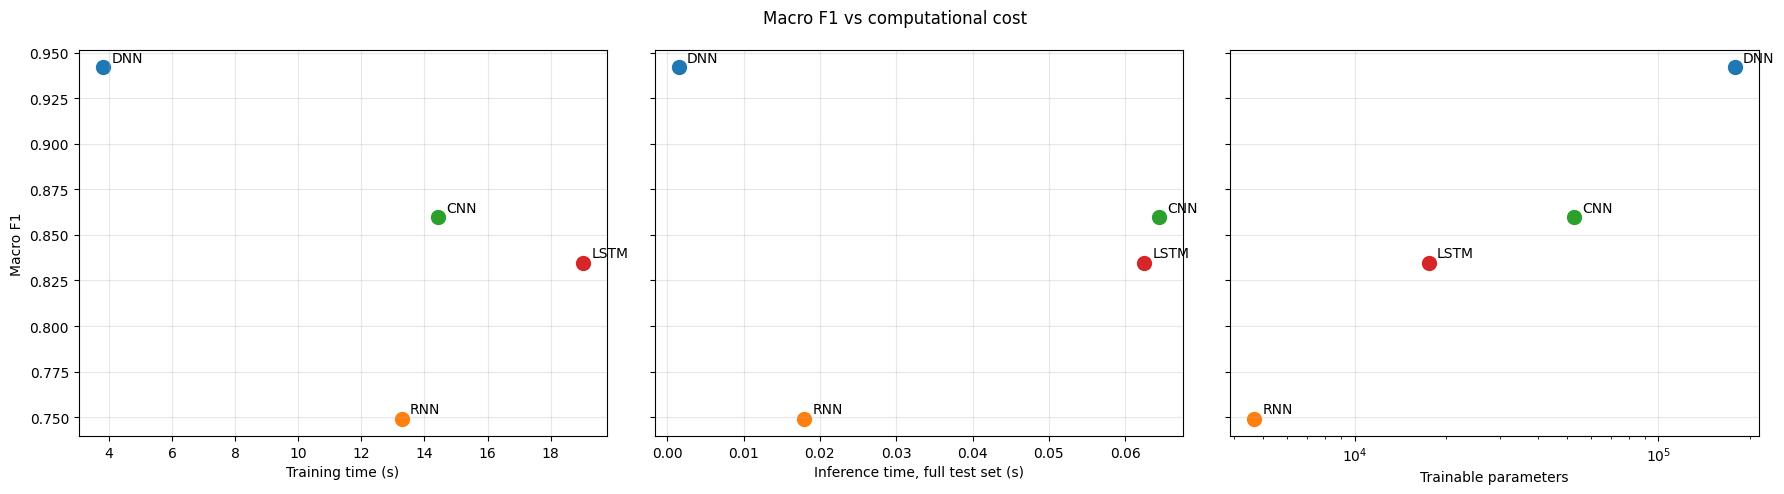

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, column, label in zip(
    axes,
    ["Training Time", "Inference Time", "Parameters"],
    ["Training time (s)", "Inference time, full test set (s)", "Trainable parameters"],
):
    for _, row in final_comparison.iterrows():
        ax.scatter(row[column], row["Macro F1"], s=100)
        ax.annotate(row["Model"], (row[column], row["Macro F1"]),
                    textcoords="offset points", xytext=(6, 4))
    ax.set_xlabel(label)
    ax.grid(alpha=0.3)
    if column == "Parameters":
        ax.set_xscale("log")

axes[0].set_ylabel("Macro F1")
fig.suptitle("Macro F1 vs computational cost")
plt.tight_layout()
plt.savefig(figures_dir / "performance_vs_cost.png", dpi=150)
plt.show()

### Performance/cost discussion

Does increased architectural complexity produce a meaningful performance improvement relative to its computational cost?


#### Performance vs. cost (seed 42)

| | DNN | RNN | CNN | LSTM |
|---|---|---|---|---|
| Test macro F1 | **0.942** | 0.749 | 0.860 | 0.835 |
| Parameters | 178 k | **4.7 k** | 53 k | 17.5 k |
| Time / epoch | **0.21 s** | 0.24 s | 0.63 s | 0.54 s |
| Total training | **3.8 s** | 13.3 s | 14.4 s | 19.0 s |
| Inference, 2,947 samples | **1.5 ms** | 18 ms | 64 ms | 63 ms |
| Peak GPU memory (train) | **20 MB** | 176 MB | 69 MB | 281 MB |

* **Parameters are not cost.** The DNN has the most parameters (10× the LSTM, 38× the RNN) and is still the cheapest model on every time and memory measure. Its forward pass is two matrix multiplications that the GPU runs fully in parallel. The RNN and LSTM have few parameters but run **561 dependent steps** in sequence, so their latency grows with sequence length and they keep activations for all steps for back-propagation (hence the higher peak memory). The CNN's cost comes from processing 561 positions with 32–128 channels.
* The DNN infers ≈ **40× faster** than the CNN and LSTM (2.0 M vs ≈ 46 k samples/s), and the RNN sits in between (164 k samples/s; its cuDNN kernel per step is far simpler than the LSTM's four gates).
* **More architectural complexity did not buy performance here.** The most structured models (CNN, LSTM) are 3–40× more expensive than the DNN and 8–11 macro-F1 points worse. The cheapest model is also the best one. Among the sequence models, the LSTM is about 2× more expensive than the RNN per epoch and is clearly worth it (+8.5 points), because gating is what makes a 561-step recursion trainable.
* These numbers come from one GPU (GTX 1650) and one seed. Training times also include early-stopping differences (18 vs 55 epochs), so the per-epoch time is the fairer cost comparison.

# Repeated Experiments: Three Random Seeds

Run the main comparison with at least:

```python
SEEDS = [1, 42, 123]
```

Instantiate a **new model** for every run.

Do not reuse previously trained weights.

In [33]:
SEEDS = [1, 42, 123]

seed_experiment_results = []
seed_histories = {}

for seed in SEEDS:
    for name in ["DNN", "RNN", "CNN", "LSTM"]:
        model = build_model(name, seed)          # fresh weights for every run
        result = fit(
            model, X_train, y_train, X_val, y_val,
            **{**TRAINING_CONFIG, "seed": seed},
        )
        val_metrics = evaluate_model(result["model"], X_val, y_val, class_names=class_names)
        test_metrics = evaluate_model(result["model"], X_test, y_test, class_names=class_names)
        seed_histories[(name, seed)] = result["history"]

        seed_experiment_results.append({
            "Seed": seed,
            "Model": name,
            "Accuracy": test_metrics["accuracy"],
            "Macro Precision": test_metrics["macro_precision"],
            "Macro Recall": test_metrics["macro_recall"],
            "Macro F1": test_metrics["macro_f1"],
            "Weighted F1": test_metrics["weighted_f1"],
            "Val Macro F1": val_metrics["macro_f1"],
            "Training Time": result["training_time"],
            "Epochs": result["epochs_completed"],
            "Best Epoch": result["best_epoch"],
            "Parameters": count_parameters(result["model"]),
            **{f"F1 {c}": f for c, f in test_metrics["per_class"]["f1"].items()},
        })
        print(f"seed {seed:3d} | {name:4s} | test macro F1 {test_metrics['macro_f1']:.4f} "
              f"| {result['epochs_completed']:3d} epochs | {result['training_time']:.1f}s")

seed   1 | DNN  | test macro F1 0.9520 |  17 epochs | 3.7s


seed   1 | RNN  | test macro F1 0.7391 |  37 epochs | 9.1s


seed   1 | CNN  | test macro F1 0.7511 |  33 epochs | 20.8s


seed   1 | LSTM | test macro F1 0.8259 |  36 epochs | 19.8s


seed  42 | DNN  | test macro F1 0.9419 |  18 epochs | 4.0s


...

seed  42 | LSTM | test macro F1 0.8347 |  35 epochs | 19.5s


seed 123 | DNN  | test macro F1 0.9460 |  26 epochs | 6.0s


seed 123 | RNN  | test macro F1 0.7259 |  25 epochs | 6.5s


seed 123 | CNN  | test macro F1 0.7645 |  20 epochs | 12.9s


seed 123 | LSTM | test macro F1 0.8379 |  50 epochs | 27.8s


# Aggregate Repeated Runs

In [34]:
seed_df = pd.DataFrame(seed_experiment_results)
seed_df[["Seed", "Model", "Accuracy", "Macro F1", "Weighted F1", "Val Macro F1",
         "Training Time", "Epochs", "Best Epoch", "Parameters"]]

,Seed,Model,Accuracy,Macro F1,Weighted F1,Val Macro F1,Training Time,Epochs,Best Epoch,Parameters
0,1,DNN,0.9522,0.9520,0.9522,0.9729,3.6866,17,7,178310
1,1,RNN,0.7469,0.7391,0.7499,0.8642,9.1253,37,27,4678
2,1,CNN,0.7805,0.7511,0.7534,0.8550,20.8378,33,23,52806
3,1,LSTM,0.8314,0.8259,0.8303,0.8930,19.8054,36,26,17542
4,42,DNN,0.9416,0.9419,0.9417,0.9762,4.0260,18,8,178310
5,42,RNN,0.7564,0.7493,0.7573,0.8760,13.7161,55,45,4678
6,42,CNN,0.8633,0.8598,0.8621,0.9304,14.6429,23,13,52806
7,42,LSTM,0.8398,0.8347,0.8388,0.8899,19.4543,35,25,17542
8,123,DNN,0.9467,0.9460,0.9466,0.9782,5.9608,26,16,178310
9,123,RNN,0.7377,0.7259,0.7369,0.8336,6.4535,25,15,4678


In [35]:
MODEL_ORDER = ["DNN", "CNN", "LSTM", "RNN"]

if not seed_df.empty:
    seed_summary = (
        seed_df
        .groupby("Model")
        .agg({
            "Accuracy": ["mean", "std"],
            "Macro F1": ["mean", "std"],
            "Weighted F1": ["mean", "std"],
            "Training Time": ["mean", "std"],
            "Epochs": ["mean", "std"],
        })
        .reindex(MODEL_ORDER)
    )

    display(seed_summary)

    # "mean ± std" view of the principal metrics
    principal = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1", "Training Time"]
    grouped = seed_df.groupby("Model")[principal]
    mean_std_table = (
        grouped.mean().map("{:.4f}".format) + " ± " + grouped.std().map("{:.4f}".format)
    ).reindex(MODEL_ORDER)
    times = seed_df.groupby("Model")["Training Time"]
    mean_std_table["Training Time"] = (
        times.mean().map("{:.1f}".format) + " ± " + times.std().map("{:.1f}".format) + " s"
    )
    display(mean_std_table)
else:
    print("Complete the repeated-seed experiment first.")

Accuracy         Macro F1         Weighted F1         Training Time  \
          mean     std     mean     std        mean     std          mean   
Model                                                                       
DNN     0.9468  0.0053   0.9466  0.0051      0.9468  0.0052        4.5578   
CNN     0.8117  0.0450   0.7918  0.0593      0.7937  0.0596       16.1335   
LSTM    0.8379  0.0058   0.8328  0.0062      0.8367  0.0056       22.3675   
RNN     0.7470  0.0093   0.7381  0.0117      0.7480  0.0104        9.7650   

                Epochs           
          std     mean      std  
Model                            
DNN    1.2268  20.3333   4.9329  
CNN    4.1642  25.3333   6.8069  
LSTM   4.7450  40.3333   8.3865  
RNN    3.6733  39.0000  15.0997

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Training Time
Model,,,,,,
DNN,0.9468 ± 0.0053,0.9490 ± 0.0032,0.9460 ± 0.0060,0.9466 ± 0.0051,0.9468 ± 0.0052,4.6 ± 1.2 s
CNN,0.8117 ± 0.0450,0.8589 ± 0.0130,0.8075 ± 0.0462,0.7918 ± 0.0593,0.7937 ± 0.0596,16.1 ± 4.2 s
LSTM,0.8379 ± 0.0058,0.8394 ± 0.0065,0.8326 ± 0.0069,0.8328 ± 0.0062,0.8367 ± 0.0056,22.4 ± 4.7 s
RNN,0.7470 ± 0.0093,0.7454 ± 0.0111,0.7364 ± 0.0112,0.7381 ± 0.0117,0.7480 ± 0.0104,9.8 ± 3.7 s


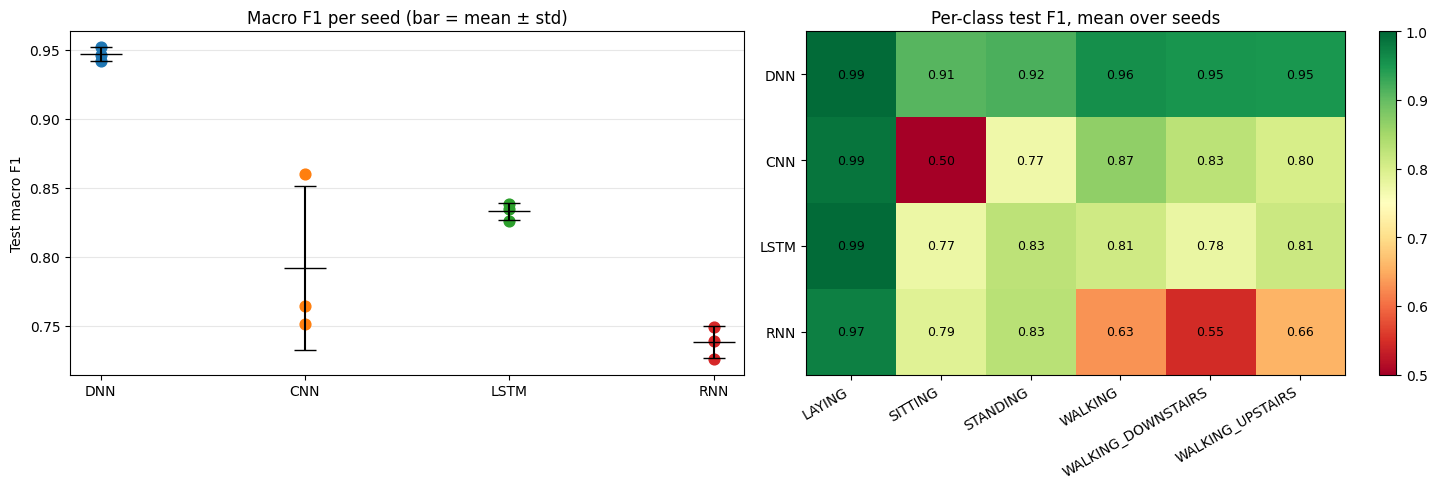

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for i, name in enumerate(MODEL_ORDER):
    values = seed_df.loc[seed_df["Model"] == name, "Macro F1"]
    axes[0].scatter(np.full(len(values), i), values, s=60, zorder=3)
    axes[0].errorbar(i, values.mean(), yerr=values.std(), fmt="_", color="black",
                     markersize=30, capsize=8, zorder=4)
axes[0].set_xticks(range(len(MODEL_ORDER)), MODEL_ORDER)
axes[0].set_ylabel("Test macro F1")
axes[0].set_title("Macro F1 per seed (bar = mean ± std)")
axes[0].grid(axis="y", alpha=0.3)

per_class_seed = (
    seed_df.groupby("Model")[[f"F1 {c}" for c in class_names]].mean().reindex(MODEL_ORDER)
)
per_class_seed.columns = class_names
im = axes[1].imshow(per_class_seed, cmap="RdYlGn", vmin=0.5, vmax=1.0, aspect="auto")
axes[1].set_xticks(range(n_classes), class_names, rotation=30, ha="right")
axes[1].set_yticks(range(len(MODEL_ORDER)), MODEL_ORDER)
for r in range(len(MODEL_ORDER)):
    for c in range(n_classes):
        axes[1].text(c, r, f"{per_class_seed.iloc[r, c]:.2f}", ha="center", va="center", fontsize=9)
axes[1].set_title("Per-class test F1, mean over seeds")
fig.colorbar(im, ax=axes[1])

plt.tight_layout()
plt.savefig(figures_dir / "seed_variability.png", dpi=150)
plt.show()

In [37]:
# Ranking of the architectures (by test macro F1) inside each seed
seed_df.pivot(index="Seed", columns="Model", values="Macro F1").rank(axis=1, ascending=False)[MODEL_ORDER]

Model,DNN,CNN,LSTM,RNN
Seed,,,,
1,1.0,3.0,2.0,4.0
42,1.0,2.0,3.0,4.0
123,1.0,3.0,2.0,4.0


### Discuss


- variability across seeds.
- whether architecture comparisons remain consistent.
- whether a conclusion based on only one run would be reliable.


#### Variability across seeds

| Model | Accuracy | Macro F1 | Weighted F1 | Training time |
|---|---|---|---|---|
| DNN | 0.947 ± 0.005 | **0.947 ± 0.005** | 0.947 ± 0.005 | 4.6 ± 1.2 s |
| LSTM | 0.838 ± 0.006 | 0.833 ± 0.006 | 0.837 ± 0.006 | 22.4 ± 4.7 s |
| CNN | 0.812 ± 0.045 | 0.792 ± 0.059 | 0.794 ± 0.060 | 16.1 ± 4.2 s |
| RNN | 0.747 ± 0.009 | 0.738 ± 0.012 | 0.748 ± 0.010 | 9.8 ± 3.7 s |

(mean ± sample standard deviation over seeds 1, 42 and 123; test set)

* **DNN, LSTM and RNN are stable.** Their macro-F1 standard deviation is 0.5–1.2 points, much smaller than the gaps between them (≥ 9 points). Their per-class F1 standard deviation across seeds is at most 0.07.
* **The CNN is not.** Its macro F1 ranges from 0.751 to 0.860 (std 5.9 points), and almost all of that variance comes from one class. SITTING F1 is 0.75 with seed 42 but 0.37 with seeds 1 and 123 (std 0.22, against ≤ 0.08 for every other class). This matches the noisy validation curve seen earlier. Because the epoch picked by early stopping lands on a noisy curve, the selected model depends on luck.
* **Ranking consistency.** The DNN ranks first and the RNN last for every seed. CNN vs LSTM is **not** consistent: the CNN wins with seed 42 (0.860 vs 0.835) but loses with seeds 1 and 123. On the mean, the LSTM is better and much more reliable.
* **Would one run have been enough?** For DNN vs the rest, or RNN vs the rest, yes, because the gaps are many standard deviations wide. For CNN vs LSTM, **no**. The seed-42 run alone, used in the first half of this notebook, suggests the CNN is the second-best architecture, and the three-seed study shows that is the less likely outcome. Any claim about models closer than a few points needs repeated runs.
* **Reproducibility check.** The seed-42 runs here reproduce the baseline runs exactly (e.g. LSTM macro F1 0.8347 in both, and again in the hidden-size-64 row of the next experiment), so `set_seed` + deterministic cuDNN makes runs fully repeatable on this machine. Training *times* vary between identical runs because of GPU state; they are not deterministic.
* **Validation vs. test.** Every model scores higher on the validation subjects than on the test subjects. The drop is about 3 points for the DNN and 6–12 points for the sequence models (CNN 0.88 → 0.79, RNN 0.86 → 0.74 macro F1). Generalising to new people is the real difficulty in this task, and the DNN handles it best.

#  Hyperparameter Experiment

Perform at least one of the following experiment.

Examples:

- DNN hidden dimension or dropout;
- RNN hidden size;
- CNN kernel size;
- CNN filter count;
- LSTM hidden size;
- batch size;
- learning rate.

Change one factor and keep other important conditions fixed.

**Selected factor: LSTM hidden size** (`hidden_size` ∈ {32, 64, 128, 256}).

The LSTM is the architecture whose cost depends most directly on one factor. With a 561-step sequence, the recurrence runs 561 sequential steps whose cost grows with `hidden_size²`, and the number of parameters grows the same way (`4·(h² + h·(input+1) + h)`). The baseline LSTM is also clearly below the DNN, so a natural question is whether it is only short of capacity.

Everything else is fixed: data split, scaler, one layer, dropout 0.2, last-state pooling, optimiser, learning rate, batch size, early stopping and the same three seeds. Model selection is based on the **validation** macro F1. The test macro F1 is reported alongside for completeness but was not used to choose anything.

In [38]:
experiment_values = [32, 64, 128, 256]
controlled_experiment_results = []

for value in experiment_values:
    for seed in SEEDS:
        model = build_model("LSTM", seed, hidden_size=value)
        result = fit(model, X_train, y_train, X_val, y_val, **{**TRAINING_CONFIG, "seed": seed})
        val_metrics = evaluate_model(result["model"], X_val, y_val)
        test_metrics = evaluate_model(result["model"], X_test, y_test)

        controlled_experiment_results.append({
            "hidden_size": value,
            "Seed": seed,
            "Parameters": count_parameters(result["model"]),
            "Val Macro F1": val_metrics["macro_f1"],
            "Test Accuracy": test_metrics["accuracy"],
            "Test Macro F1": test_metrics["macro_f1"],
            "Training Time": result["training_time"],
            "Epochs": result["epochs_completed"],
            "Time / Epoch": np.mean(result["history"]["epoch_time"]),
            "Inference Time": measure_inference_time(result["model"], X_test, device=DEVICE),
            "Train-Val acc gap": (
                result["history"]["train_accuracy"][result["best_epoch"] - 1]
                - result["history"]["val_accuracy"][result["best_epoch"] - 1]
            ),
        })
        print(f"hidden {value:3d} | seed {seed:3d} | val F1 {val_metrics['macro_f1']:.4f} "
              f"| test F1 {test_metrics['macro_f1']:.4f} | {result['training_time']:.1f}s")

controlled_df = pd.DataFrame(controlled_experiment_results)
controlled_df

hidden  32 | seed   1 | val F1 0.8629 | test F1 0.8152 | 16.0s


hidden  32 | seed  42 | val F1 0.8768 | test F1 0.8381 | 25.6s


hidden  32 | seed 123 | val F1 0.8795 | test F1 0.8251 | 29.9s


hidden  64 | seed   1 | val F1 0.8930 | test F1 0.8259 | 42.9s


hidden  64 | seed  42 | val F1 0.8899 | test F1 0.8347 | 40.8s


...

hidden 128 | seed 123 | val F1 0.8809 | test F1 0.8355 | 141.4s


hidden 256 | seed   1 | val F1 0.8981 | test F1 0.8214 | 460.5s


hidden 256 | seed  42 | val F1 0.9104 | test F1 0.8621 | 656.8s


hidden 256 | seed 123 | val F1 0.9031 | test F1 0.8323 | 382.5s


,hidden_size,Seed,Parameters,Val Macro F1,Test Accuracy,Test Macro F1,Training Time,Epochs,Time / Epoch,Inference Time,Train-Val acc gap
0,32,1,4678,0.8629,0.8212,0.8152,15.9934,32,0.4996,0.1604,-0.0128
1,32,42,4678,0.8768,0.8412,0.8381,25.5994,37,0.6917,0.0776,-0.0075
2,32,123,4678,0.8795,0.8303,0.8251,29.8766,48,0.6223,0.0716,0.0073
3,64,1,17542,0.8930,0.8314,0.8259,42.9126,36,1.1918,0.1445,-0.0114
4,64,42,17542,0.8899,0.8398,0.8347,40.8144,35,1.1659,0.1462,-0.0142
5,64,123,17542,0.8998,0.8426,0.8379,57.2130,50,1.1441,0.1446,0.0026
6,128,1,67846,0.8830,0.8235,0.8182,107.7524,25,4.3099,0.6283,-0.0157
7,128,42,67846,0.9119,0.8775,0.8752,188.3298,44,4.2801,0.6356,0.0160
8,128,123,67846,0.8809,0.8385,0.8355,141.4453,33,4.2861,0.6359,0.0163
9,256,1,266758,0.8981,0.8269,0.8214,460.4585,25,18.4182,2.1668,-0.0053


In [39]:
controlled_summary = controlled_df.groupby("hidden_size").agg({
    "Parameters": "first",
    "Val Macro F1": ["mean", "std"],
    "Test Macro F1": ["mean", "std"],
    "Training Time": ["mean", "std"],
    "Epochs": "mean",
    "Time / Epoch": "mean",
    "Inference Time": "mean",
    "Train-Val acc gap": "mean",
})
controlled_summary

Parameters Val Macro F1         Test Macro F1          \
                 first         mean     std          mean     std   
hidden_size                                                         
32                4678       0.8731  0.0089        0.8261  0.0115   
64               17542       0.8942  0.0051        0.8328  0.0062   
128              67846       0.8919  0.0173        0.8430  0.0292   
256             266758       0.9039  0.0062        0.8386  0.0211   

            Training Time             Epochs Time / Epoch Inference Time  \
                     mean       std     mean         mean           mean   
hidden_size                                                                
32                23.8231    7.1100  39.0000       0.6046         0.1032   
64                46.9800    8.9239  40.3333       1.1673         0.1451   
128              145.8425   40.4682  34.0000       4.2921         0.6333   
256              499.9011  141.3285  30.0000      16.7121         1.9365   

            Train-Val acc gap  
                         mean  
hidden_size                    
32                    -0.0044  
64                    -0.0077  
128                    0.0055  
256                    0.0063

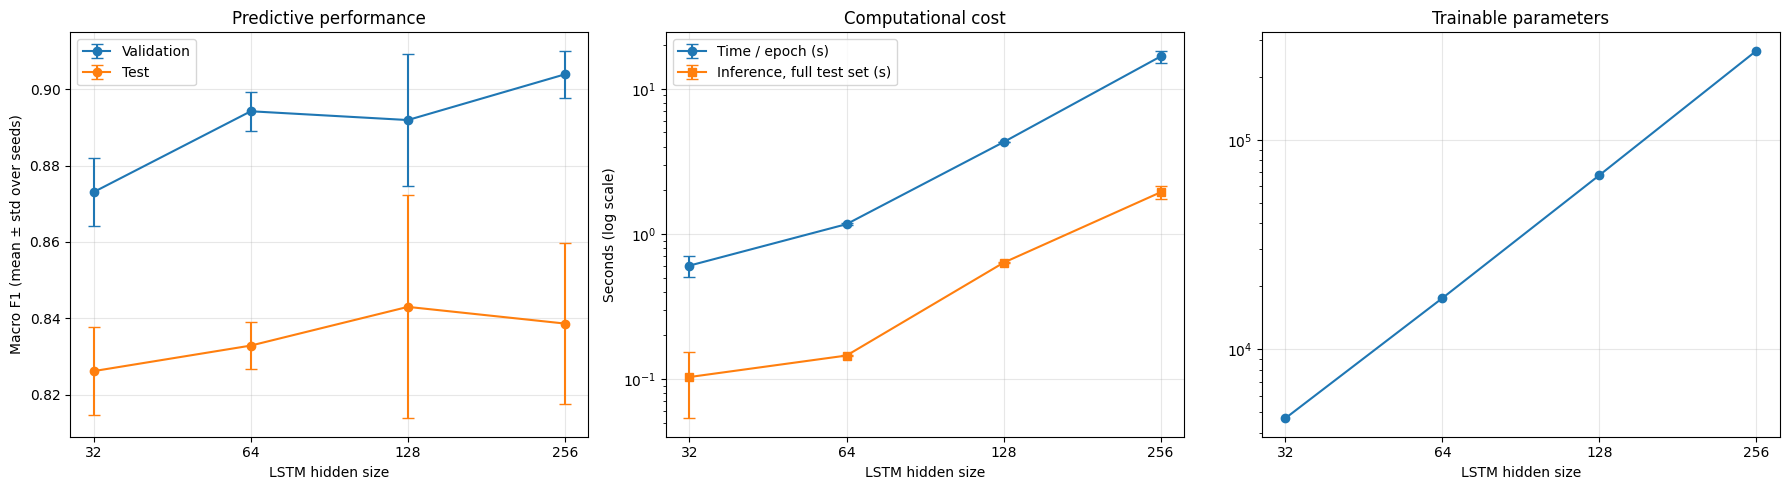

In [40]:
summary = controlled_df.groupby("hidden_size")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for column, label in [("Val Macro F1", "Validation"), ("Test Macro F1", "Test")]:
    axes[0].errorbar(experiment_values, summary[column].mean(), yerr=summary[column].std(),
                     marker="o", capsize=4, label=label)
axes[0].set_ylabel("Macro F1 (mean ± std over seeds)")
axes[0].set_title("Predictive performance")
axes[0].legend()

axes[1].errorbar(experiment_values, summary["Time / Epoch"].mean(),
                 yerr=summary["Time / Epoch"].std(), marker="o", capsize=4, label="Time / epoch (s)")
axes[1].errorbar(experiment_values, summary["Inference Time"].mean(),
                 yerr=summary["Inference Time"].std(), marker="s", capsize=4,
                 label="Inference, full test set (s)")
axes[1].set_yscale("log")
axes[1].set_ylabel("Seconds (log scale)")
axes[1].set_title("Computational cost")
axes[1].legend()

axes[2].plot(experiment_values, summary["Parameters"].first(), marker="o")
axes[2].set_yscale("log")
axes[2].set_title("Trainable parameters")

for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(experiment_values, experiment_values)
    ax.set_xlabel("LSTM hidden size")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(figures_dir / "controlled_experiment_lstm_hidden.png", dpi=150)
plt.show()

### Controlled-experiment discussion

Explain:

- the parameter selected.
- why it was selected.
- effect on predictive performance.
- effect on computational cost.
- whether larger/more complex settings consistently improved generalization.


#### Controlled experiment – LSTM hidden size

**Parameter and motivation.** `hidden_size` is the main capacity knob of the LSTM, and it drives the cost directly: parameters grow by about 4× per doubling (4.7 k → 267 k), and so does the work in each of the 561 sequential steps. The baseline LSTM (64) was underfitting slightly, so the question was whether more memory capacity closes the gap to the DNN.

| hidden | Params | Val macro F1 | Test macro F1 | Time / epoch | Train time | Inference (test set) |
|---|---|---|---|---|---|---|
| 32 | 4.7 k | 0.873 ± 0.009 | 0.826 ± 0.012 | 0.60 s | 24 s | 0.10 s |
| 64 | 17.5 k | 0.894 ± 0.005 | 0.833 ± 0.006 | 1.17 s | 47 s | 0.15 s |
| 128 | 68 k | 0.892 ± 0.017 | 0.843 ± 0.029 | 4.29 s | 146 s | 0.63 s |
| 256 | 267 k | **0.904 ± 0.006** | 0.839 ± 0.021 | 16.7 s | 500 s | 1.94 s |

**Predictive performance.**

* 32 → 64 gives a clear, consistent gain (+2.1 validation points, with small error bars). At 32 units the model is short of capacity.
* Above 64 the curve **flattens**. 128 is no better on validation than 64 (0.892 vs 0.894) and is three times as variable. 256 is the best on validation (+1.0 point over 64), but that gain is less than two standard deviations. On the test set, 128 and 256 are only 0.6–1.0 points above 64, within one standard deviation, and the improvement is driven by a single seed (seed 42: 0.875 / 0.862; seeds 1 and 123 are at or below the 64-unit values).
* Even the largest LSTM (0.84 test macro F1) remains about 11 points below the 178 k-parameter DNN (0.947). Its 267 k parameters are more than the DNN has. The LSTM's weakness on this data is its inductive bias, not its capacity.
* Larger models do not overfit more: the train–val gap stays within ±0.03. Bigger LSTMs also stop earlier (≈ 30–34 vs ≈ 40 completed epochs), but each epoch costs much more.

**Computational cost.** Going from 64 to 256 multiplies time per epoch by ≈ 14, total training time by ≈ 11, and inference time by ≈ 13, for at most a ~1-point gain. Each doubling past 64 costs ≈ 4× per epoch, in line with the `h²` growth of the recurrent matrix multiplications.

Note on timings: during this sweep the GPU ran about 2× slower than during the baseline. The identical seed-42 / 64-unit run took 1.17 s per epoch here against 0.54 s earlier, with identical accuracy, most likely because of thermal throttling on the laptop GPU. A cuDNN workspace request also hit an out-of-memory warning at size 128 and fell back to another algorithm. Compare costs *within* this table, not against the baseline table. The 4× per-doubling trend is far larger than this drift.

**Does a larger setting consistently improve generalisation?** **No.** Capacity helps up to 64 units. Beyond that, extra cost buys gains that are smaller than the seed-to-seed noise. On a validation basis, 64 is the best accuracy-to-cost choice, which justifies the baseline setting. 256 would only be chosen if its +1-point validation gain were worth a 14× higher cost.

# Save Experimental Results

In [41]:
final_comparison.to_csv(metrics_dir / "model_comparison.csv", index=False)
training_time_df.to_csv(metrics_dir / "training_time.csv", index=False)
inference_df.to_csv(metrics_dir / "inference_time.csv", index=False)
per_class_f1.to_csv(metrics_dir / "per_class_f1.csv")
confusions_df.to_csv(metrics_dir / "top_confusions.csv", index=False)

for name, result in test_results.items():
    result["per_class"].to_csv(metrics_dir / f"per_class_{name.lower()}.csv")
    pd.DataFrame(result["confusion_matrix"], index=class_names, columns=class_names).to_csv(
        metrics_dir / f"confusion_matrix_{name.lower()}.csv"
    )

for name, result in training_results.items():
    pd.DataFrame(result["history"]).rename_axis("epoch").to_csv(
        metrics_dir / f"history_{name.lower()}.csv"
    )

if "seed_df" in globals() and not seed_df.empty:
    seed_df.to_csv(metrics_dir / "seed_results.csv", index=False)
    mean_std_table.to_csv(metrics_dir / "seed_summary_mean_std.csv")

if "controlled_df" in globals() and not controlled_df.empty:
    controlled_df.to_csv(metrics_dir / "controlled_experiment.csv", index=False)

sorted(p.name for p in metrics_dir.iterdir())

['confusion_matrix_cnn.csv',
 'confusion_matrix_dnn.csv',
 'confusion_matrix_lstm.csv',
 'confusion_matrix_rnn.csv',
 'controlled_experiment.csv',
 'history_cnn.csv',
 'history_dnn.csv',
 'history_lstm.csv',
 'history_rnn.csv',
 'inference_time.csv',
 'model_comparison.csv',
 'per_class_cnn.csv',
 'per_class_dnn.csv',
 'per_class_f1.csv',
 'per_class_lstm.csv',
 'per_class_rnn.csv',
 'seed_results.csv',
 'seed_summary_mean_std.csv',
 'top_confusions.csv',
 'training_time.csv']

# Conclusions

**How do DNN, CNN, LSTM and RNN differ on this problem?** Everything below is from the experiments above (three seeds, test subjects never used for selection):

1. **Predictive performance.** DNN (macro F1 0.947 ± 0.005) ≫ LSTM (0.833 ± 0.006) > CNN (0.792 ± 0.059) > RNN (0.738 ± 0.012). Macro and weighted scores agree to within 0.01 because the classes are nearly balanced.
2. **Why.** The provided data are 561 engineered summary features, not raw time series. The order of the features only carries local meaning, so the sequence models' inductive biases (locality, translation invariance, sequential memory) add little. The fully connected DNN, which treats every feature as its own input, matches the data best. With the raw `(128, 9)` signals the ranking could well change, but those signals were not available, so this notebook cannot test that.
3. **Class-level behaviour.** LAYING is trivial for all models, static vs dynamic is almost never confused, and **SITTING vs STANDING** is the hardest pair for every architecture. The models differ in their second weakness: the RNN fails on the walking classes, the CNN is unreliable on SITTING, and the LSTM is uniformly mediocre.
4. **Computational efficiency.** The DNN is the cheapest model on every time and memory measure despite having the most parameters. The recurrent models pay for 561 sequential steps (higher latency and activation memory), and the CNN pays for 561 positions × up to 128 channels. More complexity cost more and gave less.
5. **Training behaviour and robustness.** The DNN converges in a few epochs and overfits mildly afterwards, which early stopping catches. The RNN underfits. The LSTM converges slowly but smoothly. The CNN's validation curve is very noisy, and that shows up as by far the largest variance across seeds. The CNN-vs-LSTM order flips between seeds, so a single run would have given the wrong ranking.
6. **Model complexity.** Increasing LSTM capacity beyond 64 hidden units raised cost by an order of magnitude for gains within seed noise. Even at 267 k parameters, the LSTM stays far below the DNN.

**Limitations.** Three seeds give rough standard deviations. Hyper-parameters were tuned lightly and on one validation split of five subjects. All timings come from one laptop GPU, whose clock varied during the long runs.